# Bagian E2: Naïve Bayes untuk Data Teks (Deteksi SMS Spam)

[![Buka di Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ahmad-fathan/Fundamentals-of-Data-Science/blob/main/Classification/bab-e2-naive-bayes-data-teks.ipynb)

Bagian ini menerapkan **Multinomial Naïve Bayes** pada data teks. Tugasnya adalah membedakan SMS spam dari SMS biasa. Langkahnya:

1. memuat dan mengenal dataset SMS,
2. membagi data latih dan data uji,
3. mengubah teks menjadi angka dengan *bag of words*,
4. melatih dan mengevaluasi model,
5. memprediksi SMS baru.

Bagian ini melanjutkan Bagian E1. Jalankan cell secara berurutan dari atas ke bawah. Perkiraan waktu: 25 sampai 30 menit.

## E2.1 Mengimpor Library

In [ ]:
%matplotlib inline
import pandas as pd                     # tabel data (DataFrame)
import matplotlib.pyplot as plt         # visualisasi

from sklearn.model_selection import train_test_split            # membagi data latih dan uji
from sklearn.feature_extraction.text import CountVectorizer     # teks -> hitungan kata
from sklearn.naive_bayes import MultinomialNB                   # Naive Bayes untuk hitungan kata
from sklearn.pipeline import make_pipeline                      # merangkai vektorisasi + model
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

print("Library berhasil diimpor")

Library berhasil diimpor


## E2.2 Mengenal Dataset SMS

Dataset yang dipakai adalah **SMS Spam Collection** (Almeida dan Hidalgo, 2011), berisi 5.572 SMS berbahasa Inggris. Setiap SMS diberi label:

- `ham` = SMS biasa (bukan spam)
- `spam` = SMS spam, misalnya iklan, undian palsu, atau penipuan

In [ ]:
url = "https://raw.githubusercontent.com/justmarkham/pycon-2016-tutorial/master/data/sms.tsv"
sms = pd.read_csv(url, sep="\t", header=None, names=["label", "message"])

print("Ukuran data:", sms.shape)
sms.head()

Ukuran data: (5572, 2)


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


label
ham     4825
spam     747
Name: count, dtype: int64


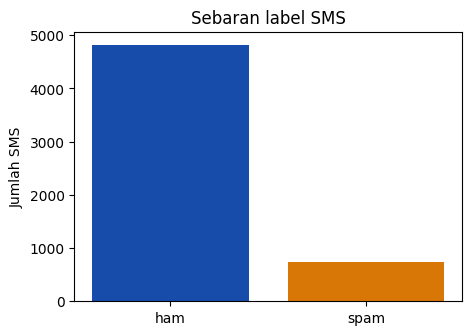

In [ ]:
jumlah = sms["label"].value_counts()
print(jumlah)

plt.figure(figsize=(5, 3.5))
plt.bar(jumlah.index, jumlah.values, color=["#174CAA", "#D97706"])
plt.ylabel("Jumlah SMS")
plt.title("Sebaran label SMS")
plt.show()

Hanya sekitar 13 persen SMS yang berlabel spam. Data seperti ini disebut **tidak seimbang** (*imbalanced*). Model yang selalu menjawab `ham` sudah benar sekitar 87 persen, padahal tidak pernah menemukan satu spam pun. Karena itu, di E2.6 juga dilihat *precision* dan *recall* untuk kelas spam.

Berikut beberapa contoh SMS spam:

In [ ]:
for pesan in sms.loc[sms["label"] == "spam", "message"].head(4):
    print("-", pesan)

- Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's apply 08452810075over18's
- FreeMsg Hey there darling it's been 3 week's now and no word back! I'd like some fun you up for it still? Tb ok! XxX std chgs to send, £1.50 to rcv
- WINNER!! As a valued network customer you have been selected to receivea £900 prize reward! To claim call 09061701461. Claim code KL341. Valid 12 hours only.
- Had your mobile 11 months or more? U R entitled to Update to the latest colour mobiles with camera for Free! Call The Mobile Update Co FREE on 08002986030


## E2.3 Membagi Data Latih dan Data Uji

Data dibagi **sebelum** teks diolah, supaya model tidak "mengintip" kata-kata dari data uji. `stratify=y` menjaga proporsi spam tetap sekitar 13 persen di kedua bagian.

In [ ]:
X = sms["message"]     # teks SMS
y = sms["label"]       # ham atau spam

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

print("Data latih:", len(X_train), "| data uji:", len(X_test))

Data latih: 4457 | data uji: 1115


## E2.4 Dari Teks ke Angka: *Bag of Words*

Model tidak dapat membaca kalimat. Dengan *bag of words*, setiap kata menjadi satu fitur, dan nilainya adalah **berapa kali kata itu muncul** dalam sebuah SMS. `CountVectorizer` sekaligus mengubah huruf menjadi huruf kecil dan membuang *stop words*, yaitu kata umum seperti *the*, *is*, dan *to*.

Berikut contohnya pada tiga SMS kecil.

In [ ]:
contoh = [
    "FREE prize! Claim your free prize now",
    "Are we still meeting for lunch?",
    "Free lunch at the meeting today",
]

vec_contoh = CountVectorizer(stop_words="english")
matriks = vec_contoh.fit_transform(contoh)

pd.DataFrame(matriks.toarray(), columns=vec_contoh.get_feature_names_out(),
             index=["SMS 1", "SMS 2", "SMS 3"])

,claim,free,lunch,meeting,prize,today
SMS 1,1,2,0,0,2,0
SMS 2,0,0,1,1,0,0
SMS 3,0,1,1,1,0,1


Setiap baris adalah satu SMS dan setiap kolom adalah satu kata. Pada SMS 1, kata `free` dan `prize` masing-masing muncul 2 kali. Pada data sebenarnya, jumlah kolomnya mencapai ribuan kata.

## E2.5 Melatih Model

`make_pipeline` merangkai `CountVectorizer` dan `MultinomialNB` menjadi satu model, sehingga teks mentah dapat langsung dimasukkan. Model menghitung probabilitas setiap kata pada kelas spam dan ham; rumusnya dibahas di modul.

Parameter `alpha=1` adalah **Laplace smoothing**, seperti di modul. Smoothing ini mencegah kata yang tidak pernah muncul di satu kelas membuat seluruh skornya bernilai nol.

In [ ]:
model = make_pipeline(
    CountVectorizer(stop_words="english"),
    MultinomialNB(alpha=1.0),
)
model.fit(X_train, y_train)

print("Model selesai dilatih.")

Model selesai dilatih.


## E2.6 Mengevaluasi Model

In [ ]:
y_pred = model.predict(X_test)

print(f"Akurasi data uji: {accuracy_score(y_test, y_pred):.3f}")
print()
print(classification_report(y_test, y_pred, digits=3))

Akurasi data uji: 0.985

              precision    recall  f1-score   support

         ham      0.988     0.995     0.991       966
        spam      0.965     0.919     0.942       149

    accuracy                          0.985      1115
   macro avg      0.976     0.957     0.966      1115
weighted avg      0.985     0.985     0.985      1115



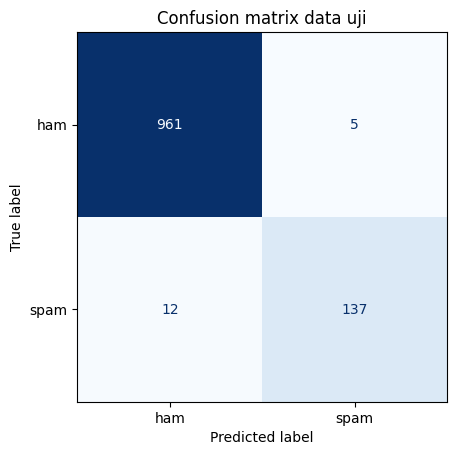

In [ ]:
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, cmap="Blues", colorbar=False)
plt.title("Confusion matrix data uji")
plt.show()

Akurasinya sekitar 98,5 persen, jauh di atas model "selalu ham" yang hanya 87 persen. Untuk kelas spam, perhatikan dua angka berikut:

- **Precision spam** (sekitar 0,96): dari semua SMS yang ditandai spam, berapa yang benar-benar spam. Kesalahannya adalah SMS biasa yang ikut masuk folder spam (baris `ham`, kolom `spam`).
- **Recall spam** (sekitar 0,92): dari semua spam yang sebenarnya, berapa yang berhasil ditangkap. Kesalahannya adalah spam yang lolos ke kotak masuk (baris `spam`, kolom `ham`).

## E2.7 Memprediksi SMS Baru

Karena vektorisasi dan model sudah dirangkai dalam satu *pipeline*, SMS baru cukup diberikan dalam bentuk teks biasa.

In [ ]:
sms_baru = [
    "Congratulations! You have won a FREE prize. Call now to claim",
    "Hi, are we still meeting for lunch tomorrow?",
    "URGENT: your account will be suspended, reply YES to keep it active",
]

for pesan, label in zip(sms_baru, model.predict(sms_baru)):
    print(f"[{label:4s}] {pesan}")

[spam] Congratulations! You have won a FREE prize. Call now to claim
[ham ] Hi, are we still meeting for lunch tomorrow?
[spam] URGENT: your account will be suspended, reply YES to keep it active


Silakan coba SMS buatan sendiri pada cell berikut. Di Google Colab, kolom isian akan muncul di sebelah kanan cell.

In [ ]:
pesan_saya = "Your free ringtone is waiting, text TONE to 8007 to claim"  # @param {type:"string"}

print("Prediksi:", model.predict([pesan_saya])[0])

Prediksi: spam


## E2.8 Latihan

Kerjakan latihan berikut di cell kosong yang tersedia. Gunakan pembagian data latih dan data uji yang sama.

**Latihan 1.** Di modul, Bernoulli Naïve Bayes hanya memperhatikan apakah sebuah kata muncul atau tidak. Ganti model dengan `BernoulliNB` (impor dari `sklearn.naive_bayes`) dan gunakan `CountVectorizer(stop_words="english", binary=True)`. Bandingkan hasilnya dengan model Multinomial.

*Hasil yang diharapkan:* akurasi sekitar 0,97, sedikit di bawah Multinomial, dengan *recall* spam turun menjadi sekitar 0,78. Jelaskan mengapa informasi "berapa kali kata muncul" membantu pada data ini.

Akurasi Bernoulli: 0.9704035874439462

              precision    recall  f1-score   support

         ham      0.967     1.000     0.983       966
        spam      1.000     0.779     0.875       149

    accuracy                          0.970      1115
   macro avg      0.983     0.889     0.929      1115
weighted avg      0.971     0.970     0.969      1115



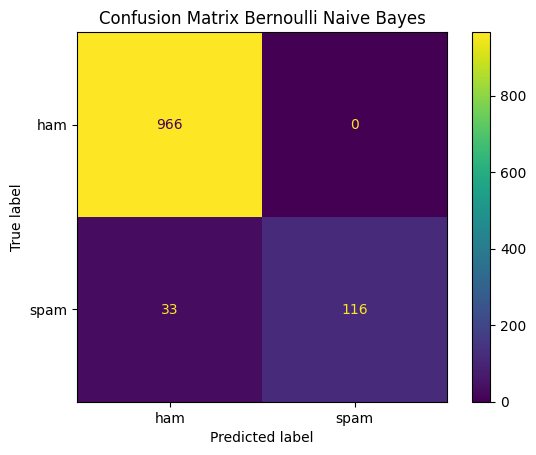

In [ ]:

# Latihan 1

from sklearn.naive_bayes import BernoulliNB
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, classification_report
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Membuat model Bernoulli Naive Bayes
model_bernoulli = make_pipeline(
    CountVectorizer(stop_words="english", binary=True),
    BernoulliNB(alpha=1.0)
)

# Melatih model
model_bernoulli.fit(X_train, y_train)

# Melakukan prediksi
y_pred_bernoulli = model_bernoulli.predict(X_test)

# Evaluasi model
print("Akurasi Bernoulli:", accuracy_score(y_test, y_pred_bernoulli))
print()
print(classification_report(y_test, y_pred_bernoulli, digits=3))

# Confusion Matrix
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_bernoulli
)
plt.title("Confusion Matrix Bernoulli Naive Bayes")
plt.show()



**Latihan 2.** Tulis paling sedikit lima SMS buatan sendiri, campuran spam dan bukan spam, lalu prediksi dengan model di E2.5. Adakah SMS yang diprediksi salah? Jelaskan kemungkinan penyebabnya dengan melihat kata-kata di dalamnya.

In [ ]:

# Latihan 2

# Membuat 5 contoh SMS sendiri
sms_saya = [
    "Congratulations! You have won a free prize. Call now!",
    "Hi, are we still meeting for lunch tomorrow?",
    "URGENT! Claim your free cash reward now!",
    "Don't forget to bring your book to class tomorrow.",
    "You have won a lottery! Reply YES to claim your prize."
]

# Melakukan prediksi menggunakan model E2.5
prediksi = model.predict(sms_saya)

# Menampilkan hasil prediksi
for pesan, label in zip(sms_saya, prediksi):
    print(f"Prediksi: {label.upper()}")
    print(f"Pesan: {pesan}")
    print("-" * 60)



Prediksi: SPAM
Pesan: Congratulations! You have won a free prize. Call now!
------------------------------------------------------------
Prediksi: HAM
Pesan: Hi, are we still meeting for lunch tomorrow?
------------------------------------------------------------
Prediksi: SPAM
Pesan: URGENT! Claim your free cash reward now!
------------------------------------------------------------
Prediksi: HAM
Pesan: Don't forget to bring your book to class tomorrow.
------------------------------------------------------------
Prediksi: SPAM
Pesan: You have won a lottery! Reply YES to claim your prize.
------------------------------------------------------------


Selanjutnya, **Bagian E3** menerapkan Naïve Bayes pada data kesehatan yang tidak seimbang.